# SmartFood · Filtrado colaborativo con NMF

Explorar factores latentes y recomendaciones por vecinos. La comparación del grid se interpreta automáticamente durante la ejecución; consulta docs/evaluacion.md para las limitaciones metodológicas.

**Estado:** ejecución completa mediante el maestro el 6 de octubre de 2026. Los resultados son exploratorios; consulta el registro de ejecución y la evaluación para interpretar sus límites.

**Archivo:** `04_filtrado_colaborativo_nmf.ipynb`. Consulta la [guía de ejecución](../docs/notebooks.md) para conocer entradas, salidas y precauciones.


In [1]:
# Resolver la raíz del proyecto desde Jupyter o desde la carpeta del proyecto.
from pathlib import Path
import os
import sys

def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("smartfood")
if PROJECT_ROOT is None:
    raise RuntimeError("Inicia Jupyter desde la carpeta SmartFood o notebooks.")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
for folder in ("data/intermediate", "data/processed", "data/output", "reports", "models"):
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)

# Configuracion comun: registrar avisos para el resumen de alertas.
from smartfood.entorno_notebook import configurar_notebook
configurar_notebook()


## ✅ Paso 1: Carga de librerías

In [2]:
import pandas as pd
import numpy as np
from sklearn.decomposition import NMF
from sklearn.metrics import mean_squared_error
# from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split

from smartfood.recomendaciones_nmf import (
    calcular_similitud_coseno,
    obtener_mas_similares,
    generar_recomendaciones,
    visualizar_recomendaciones,
    predecir_rating,
    # evaluar_modelo,
    evaluar_nmf_con_mascara,
    grid_nmf,
    graficar_resultados_grid,
    # entrenar_y_exportar_nmf,
    entrenar_y_exportar_nmf_desde_grid
)
import scipy.sparse as sp 


## ✅ Paso 2: Carga de datos

In [3]:
# Cargar datos
recipes = pd.read_parquet("data/processed/recipes_filtrado.parquet")
print("Data shape: ", recipes.shape)
reviews = pd.read_parquet("data/processed/reviews_filtrado.parquet")
print("Data shape: ", reviews.shape)

Data shape:  (190, 28)
Data shape:  (10343, 8)


## ✅ Paso 3: Construcción de la matriz usuario-receta

En este caso tendremos que hacer una imputación, pero, claro queda decidir cual podría ser

📊 Cuadro comparativo de métodos de imputación en sistemas de recomendación

| Método                     | ¿Qué significa?                                                             | Ventajas                                                                 | Desventajas                                                            | Ideal para...                                 |
|---------------------------|-----------------------------------------------------------------------------|--------------------------------------------------------------------------|------------------------------------------------------------------------|------------------------------------------------|
| **0 (cero)**              | No hay interacción.                                                         | ✅ Simple y rápido<br>✅ Compatible con NMF y modelos implícitos          | ⚠️ Puede ser interpretado como una calificación real (neutral o mala) | Modelos implícitos o NMF                      |
| **Media del usuario**     | El usuario daría una calificación similar a su promedio.                    | ✅ Personaliza la imputación<br>✅ Refleja tendencias personales          | ⚠️ Refuerza sesgos del usuario                                           | KNN centrado, datasets con usuarios densos     |
| **Media global**          | Se asume una calificación estándar para todos.                              | ✅ Neutral y simple<br>✅ Útil como baseline                              | ⚠️ Suaviza diferencias<br>⚠️ Oculta patrones                             | Comparaciones base, modelos simples            |
| **Media del ítem**        | Se le asigna al usuario la nota promedio que otros dieron a la receta.      | ✅ Útil en cold start<br>✅ Capta la “popularidad” del ítem               | ⚠️ Ignora preferencias del usuario                                     | Cold start, perfilado de ítems                 |
| **Valor intermedio (ej: 3)** | Se impone un valor central del rango (0 a 5).                                 | ✅ Mantiene rango numérico<br>✅ Muy útil si no hay contexto               | ⚠️ Puede no tener sentido con sesgo fuerte (como ratings centrados en 5) | Modelos simples o implícitos en casos extremos |


In [4]:
# 1. Crear matriz usuario-receta
matriz_ratings = reviews.pivot_table(index='authorid', columns='recipeid', values='rating')

# 2. Imputación con ceros (necesario para NMF)
matriz_ratings_filled = matriz_ratings.fillna(0)

In [5]:
# 3. Confirmar dimensiones y sparsity
n_users, n_items = matriz_ratings_filled.shape
n_interacciones = (matriz_ratings_filled > 0).sum().sum()
sparsity = 1 - (n_interacciones / (n_users * n_items))

print(f"👥 Usuarios: {n_users}")
print(f"📦 Recetas: {n_items}")
print(f"⭐ Interacciones: {n_interacciones}")
print(f"🌫️ Sparsity: {sparsity:.2%}")

👥 Usuarios: 617
📦 Recetas: 190
⭐ Interacciones: 10175
🌫️ Sparsity: 91.32%


In [6]:
resultado = evaluar_nmf_con_mascara(
    matriz_original=matriz_ratings_filled,
    porcentaje_test=0.2,
    n_componentes=20,
    random_state=42
)

print(pd.json_normalize(resultado).T.to_markdown(index=True))


|                    |          0 |
|:-------------------|-----------:|
| mse                |   18.4199  |
| rmse               |    4.29185 |
| interacciones_test | 2035       |
| componentes        |   20       |


In [7]:
max_componentes_validos = min(matriz_ratings_filled.shape)
print(f"🎯 Máximo permitido para n_components con 'nndsvda': {max_componentes_validos}")

componentes = list(range(10, max_componentes_validos + 1, 10))

# Configuracion historica (70 componentes); la celda siguiente ejecuta el grid y la interpretacion (comentario_nmf) compara dinamicamente si esta eleccion minimiza el RMSE.
componentes_seleccionados = 70


🎯 Máximo permitido para n_components con 'nndsvda': 190


🔧 Evaluando NMF con 10 componentes...
🔧 Evaluando NMF con 20 componentes...
🔧 Evaluando NMF con 30 componentes...


🔧 Evaluando NMF con 40 componentes...


🔧 Evaluando NMF con 50 componentes...


🔧 Evaluando NMF con 60 componentes...


🔧 Evaluando NMF con 70 componentes...


...

🔧 Evaluando NMF con 160 componentes...


🔧 Evaluando NMF con 170 componentes...


🔧 Evaluando NMF con 180 componentes...


🔧 Evaluando NMF con 190 componentes...


|   componentes |     mse |    rmse |   interacciones_test |   tiempo | init    | solver   |   max_iter |   alpha_W |   alpha_H |   l1_ratio |
|--------------:|--------:|--------:|---------------------:|---------:|:--------|:---------|-----------:|----------:|----------:|-----------:|
|           130 | 21.2276 | 4.60734 |                 2035 |     0.28 | nndsvda | mu       |       1000 |      0.01 |      0.01 |        0.5 |
|           140 | 21.161  | 4.60011 |                 2035 |     0.55 | nndsvda | mu       |       1000 |      0.01 |      0.01 |        0.5 |
|           190 | 21.1063 | 4.59416 |                 2035 |     0.56 | nndsvda | mu       |       1000 |      0.01 |      0.01 |        0.5 |
|           180 | 21.0875 | 4.59212 |                 2035 |     0.52 | nndsvda | mu       |       1000 |      0.01 |      0.01 |        0.5 |
|           170 | 21.0795 | 4.59125 |                 2035 |     0.58 | nndsvda | mu       |       1000 |      0.01 |      0.01 |        0.5 |

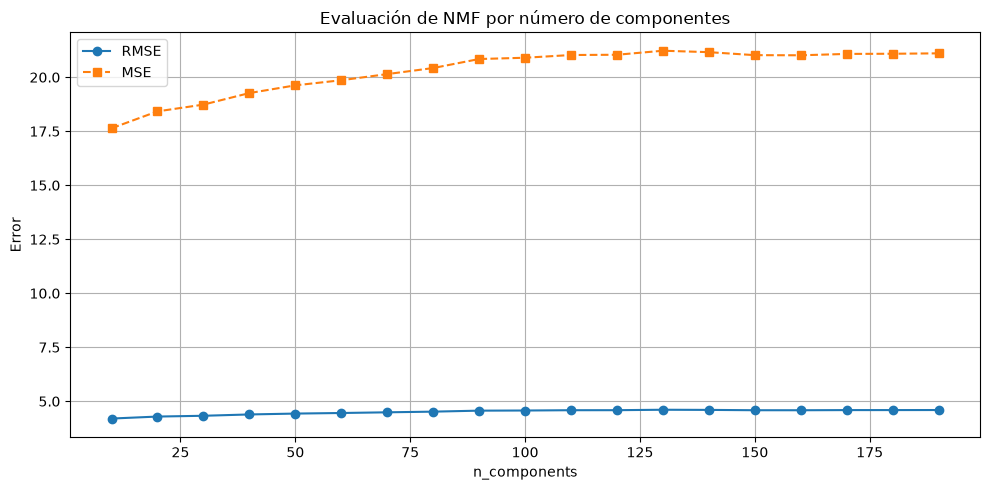

In [8]:
resultados_nmf = grid_nmf(
    matriz_ratings=matriz_ratings_filled
    , componentes=componentes
    , porcentaje_test=0.2
)

print(resultados_nmf.sort_values(by='rmse', ascending=False).to_markdown(index=True))
graficar_resultados_grid(resultados_nmf)


In [9]:
from IPython.display import Markdown, display
from smartfood.anotaciones import comentario_nmf
display(Markdown(comentario_nmf(resultados_nmf, componentes_seleccionados)))

from smartfood.informe import registrar_etapa
registrar_etapa(PROJECT_ROOT, "modelado", {"componentes_seleccionados": int(componentes_seleccionados), "grid": resultados_nmf.reset_index().to_dict(orient="records")}, comentario_nmf(resultados_nmf, componentes_seleccionados), "04_filtrado_colaborativo_nmf.ipynb")


### Interpretación del grid NMF

El menor RMSE es **4,1996**, con **10 componentes**. La configuración seleccionada (70 componentes, RMSE 4,4884) no minimiza el error del grid. Este resultado compara las configuraciones evaluadas; no determina un óptimo universal. El grid reutiliza las interacciones ocultas: hace falta un test independiente y baselines. El RMSE de reconstrucción no mide la calidad del ranking por vecinos.

In [10]:
resultados_nmf_filter = resultados_nmf[resultados_nmf.index == componentes_seleccionados]

U, I, pred_df = entrenar_y_exportar_nmf_desde_grid(
    matriz_ratings_filled,
    df_resultados_grid=resultados_nmf_filter,
    guardar=True
)

📌 Usando configuración óptima:
rmse         4.4884
init        nndsvda
solver           mu
max_iter       1000
alpha_W        0.01
alpha_H        0.01
l1_ratio        0.5
Name: 70, dtype: object
🚀 Entrenando NMF con 70 componentes...


💾 Embeddings y predicciones guardadas en disco.


In [11]:
# U: embeddings de usuarios (indexados por AuthorId)
similitud_usuarios = calcular_similitud_coseno(U)

In [12]:
# I: embeddings de recetas (indexados por RecipeId)
similitud_recetas = calcular_similitud_coseno(I)

## ✅ Paso 4: Ejemplo de recomendaciones

✅ Recomendaciones de usuario

In [13]:
usuario_ejemplo = U.index[3]
nombre_usuario =reviews.loc[reviews["authorid"] == usuario_ejemplo, "authorname"].values[0]
recs = generar_recomendaciones(usuario_ejemplo, matriz_ratings_filled, similitud_usuarios, top_n=5)
visualizar_recomendaciones(nombre_usuario, recs, recipes, tipo="usuario")


📌 Recomendaciones para el usuario baby kato:
1. crock pot whole chicken (Score: 3.76)
2. steak marinade (Score: 2.93)
3. awesome baked pork chops (Score: 2.52)
4. ovenfried chicken chimichangas (Score: 2.48)
5. mamas supper club tilapia parmesan (Score: 2.48)


In [14]:
usuario_ejemplo = U.index[25]
nombre_usuario =reviews.loc[reviews["authorid"] == usuario_ejemplo, "authorname"].values[0]
recs = generar_recomendaciones(usuario_ejemplo, matriz_ratings_filled, similitud_usuarios, top_n=5)
visualizar_recomendaciones(nombre_usuario, recs, recipes, tipo="usuario")


📌 Recomendaciones para el usuario rosslare:
1. creamy burrito casserole (Score: 3.42)
2. bourbon chicken (Score: 3.41)
3. pork chops yumyum (Score: 3.11)
4. buffalo chicken dip (Score: 3.06)
5. funky chicken with sesame noodles (Score: 2.83)


✅ Recomendaciones de recetas

In [15]:
receta_ejemplo = I.index[0]
nombre_receta = recipes.loc[recipes["recipeid"] == receta_ejemplo, "name"].values[0]
# Similares a una receta (con nombre)
similares = obtener_mas_similares(receta_ejemplo, similitud_recetas, df_nombres = recipes, col_id = "recipeid", col_nombre = "name")
print(f"🔎 Recetas similares a la receta {nombre_receta}:")
for i, (id_receta, nombre, score) in enumerate(similares, 1):
    print(f"{i}. {nombre} (Score: {score})")


🔎 Recetas similares a la receta bourbon chicken:
1. crockpot chicken with black beans amp cream cheese (Score: 0.17)
2. the best chili you will ever taste (Score: 0.14)
3. crockpot potato chowder (Score: 0.12)
4. chicken tortilla soup ii (Score: 0.12)
5. classic potato salad (Score: 0.12)


In [16]:
receta_ejemplo = I.index[180]
nombre_receta = recipes.loc[recipes["recipeid"] == receta_ejemplo, "name"].values[0]
# Similares a una receta (con nombre)
similares = obtener_mas_similares(receta_ejemplo, similitud_recetas, df_nombres = recipes, col_id = "recipeid", col_nombre = "name")
print(f"🔎 Recetas similares a la receta {nombre_receta}:")
for i, (id_receta, nombre, score) in enumerate(similares, 1):
    print(f"{i}. {nombre} (Score: {score})")


🔎 Recetas similares a la receta taco seasoning mix:
1. bevs spaghetti sauce (Score: 0.49)
2. petes scratch pancakes (Score: 0.32)
3. perfect chocolate brownies (Score: 0.19)
4. crock pot lasagna (Score: 0.18)
5. easy and tasty barbecue chicken sandwiches in the crock pot (Score: 0.18)


✅ Prediccion

In [17]:
usuario = U.index[0]
receta = I.index[0]

pred = predecir_rating(
    user=usuario,
    item=receta,
    matriz=pred_df,
    similitud=similitud_usuarios,
    k=5
)

nombre_usuario =reviews.loc[reviews["authorid"] == usuario, "authorname"].values[0]
nombre_receta = recipes.loc[recipes["recipeid"] == receta, "name"].values[0]

print(f"Predicción para el usuario {nombre_usuario} sobre la receta {nombre_receta}: {pred:.2f}")

Predicción para el usuario sydney mike sobre la receta bourbon chicken: 1.36


In [18]:
usuario = U.index[50]
receta = I.index[150]

pred = predecir_rating(
    user=usuario,
    item=receta,
    matriz=pred_df,
    similitud=similitud_usuarios,
    k=5
)

nombre_usuario =reviews.loc[reviews["authorid"] == usuario, "authorname"].values[0]
nombre_receta = recipes.loc[recipes["recipeid"] == receta, "name"].values[0]

print(f"Predicción para el usuario {nombre_usuario} sobre la receta {nombre_receta}: {pred:.2f}")

Predicción para el usuario bluemoon downunder sobre la receta amazing puff balls: 0.11


## Alertas de la ejecución

La tabla agrupa los avisos de Python y conserva su detalle original. Si una celda falla antes de llegar aquí, puedes ejecutar esta celda de resumen para consultar las alertas ya registradas. Los errores y los mensajes de diagnóstico impresos no se incluyen automáticamente.


In [19]:
from smartfood.entorno_notebook import mostrar_alertas
mostrar_alertas(PROJECT_ROOT / "reports" / "alertas" / "04_filtrado_colaborativo_nmf.json")
from smartfood.informe import generar_informe
generar_informe(PROJECT_ROOT)


WindowsPath('D:/portafolio/Analisis/Recommenders/SmartFood/reports/informe_final/informe_final.md')